<a href="https://colab.research.google.com/github/AjurshaDahal/house-price-prediction/blob/main/housepriceprediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Imports


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Data preprocessing

In [ ]:

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer


models used for model selection

In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor


metrics used


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

configuration


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving housing.csv to housing (4).csv


In [ ]:
data = pd.read_csv("housing.csv")

In [ ]:
data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [ ]:
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [ ]:
data.dropna(inplace = True)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20433 non-null  float64
 1   latitude            20433 non-null  float64
 2   housing_median_age  20433 non-null  float64
 3   total_rooms         20433 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20433 non-null  float64
 6   households          20433 non-null  float64
 7   median_income       20433 non-null  float64
 8   median_house_value  20433 non-null  float64
 9   ocean_proximity     20433 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.7+ MB


Spliting into train and test


In [ ]:
from sklearn.model_selection import train_test_split

x=data.drop(['median_house_value'],axis=1)
y = data['median_house_value']


In [ ]:
x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.2)

joining the x into y to analysis basic corelation


In [ ]:
train_data = x_train.join(y_train)

In [ ]:
train_data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,median_house_value
5679,-118.29,33.71,40.0,1644.0,471.0,780.0,416.0,3.1071,NEAR OCEAN,464300.0
16332,-121.34,38.03,20.0,4213.0,751.0,2071.0,714.0,4.4063,INLAND,130800.0
693,-122.11,37.70,23.0,1689.0,461.0,828.0,443.0,2.1552,NEAR BAY,161400.0
1672,-122.20,38.04,31.0,3029.0,500.0,1236.0,487.0,5.6022,NEAR BAY,197000.0
1548,-121.94,37.75,17.0,2559.0,370.0,1238.0,377.0,6.2781,<1H OCEAN,269800.0
...,...,...,...,...,...,...,...,...,...,...
5578,-118.30,33.85,38.0,123.0,36.0,142.0,40.0,2.3942,<1H OCEAN,200000.0
15120,-116.93,32.85,5.0,4116.0,990.0,2770.0,905.0,3.1142,<1H OCEAN,150000.0
16593,-121.42,37.73,2.0,2682.0,393.0,883.0,271.0,5.9934,INLAND,196700.0
4876,-118.28,34.03,25.0,1407.0,550.0,1193.0,472.0,1.2989,<1H OCEAN,225000.0


array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

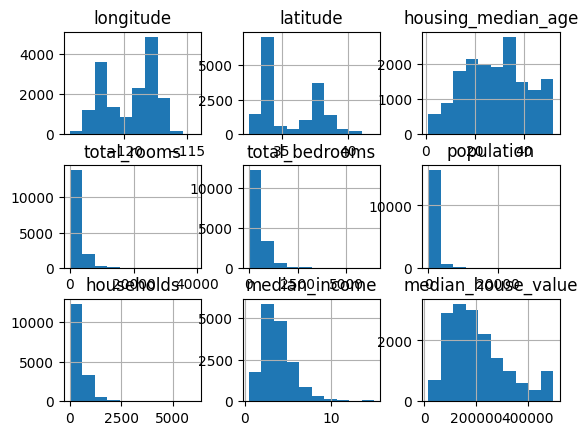

In [ ]:
train_data.hist()

<Axes: >

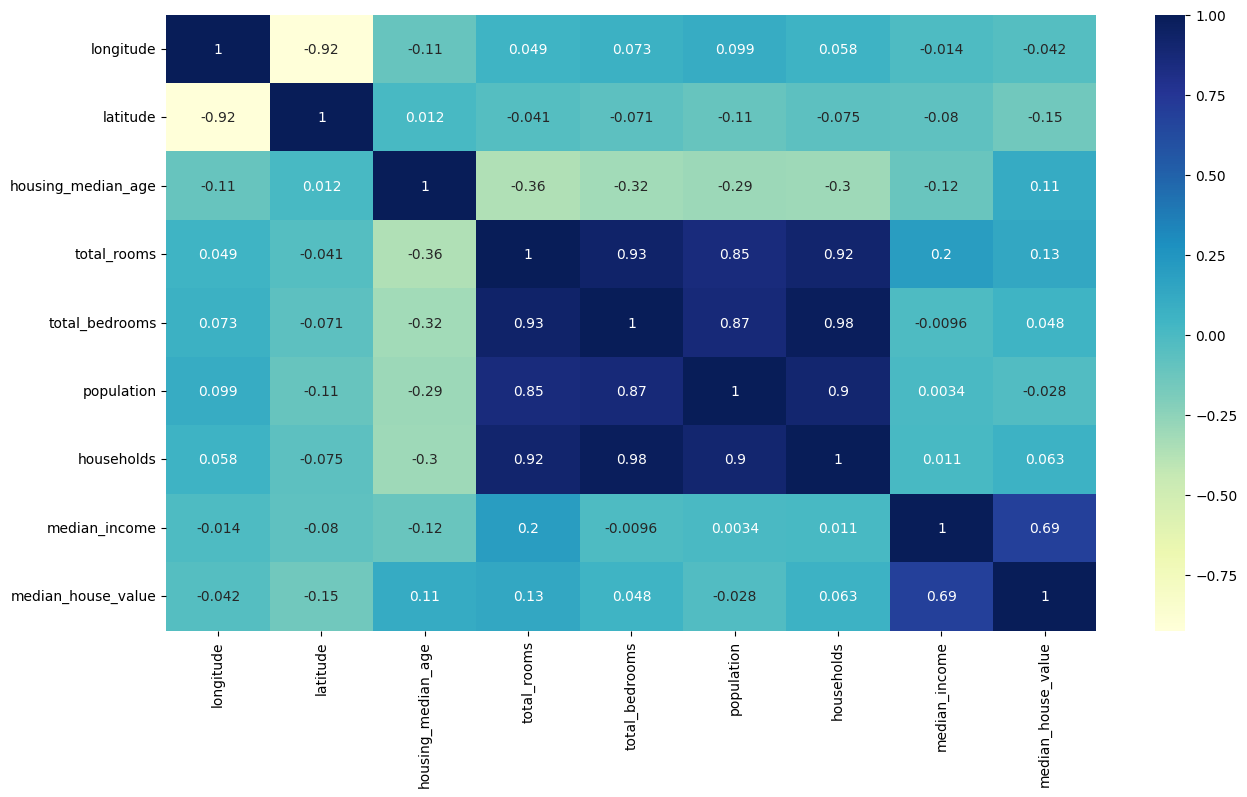

In [ ]:
plt.figure(figsize=(15,8))
sns.heatmap(train_data.select_dtypes(include='number').corr(),
            annot=True,
            cmap="YlGnBu")



Preprocessing


In [ ]:
train_data['total_rooms']=np.log(train_data['total_rooms']+1)
train_data['total_bedrooms']=np.log(train_data['total_bedrooms']+1)
train_data['population']=np.log(train_data['population']+1)
train_data['households']=np.log(train_data['households']+1)


array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

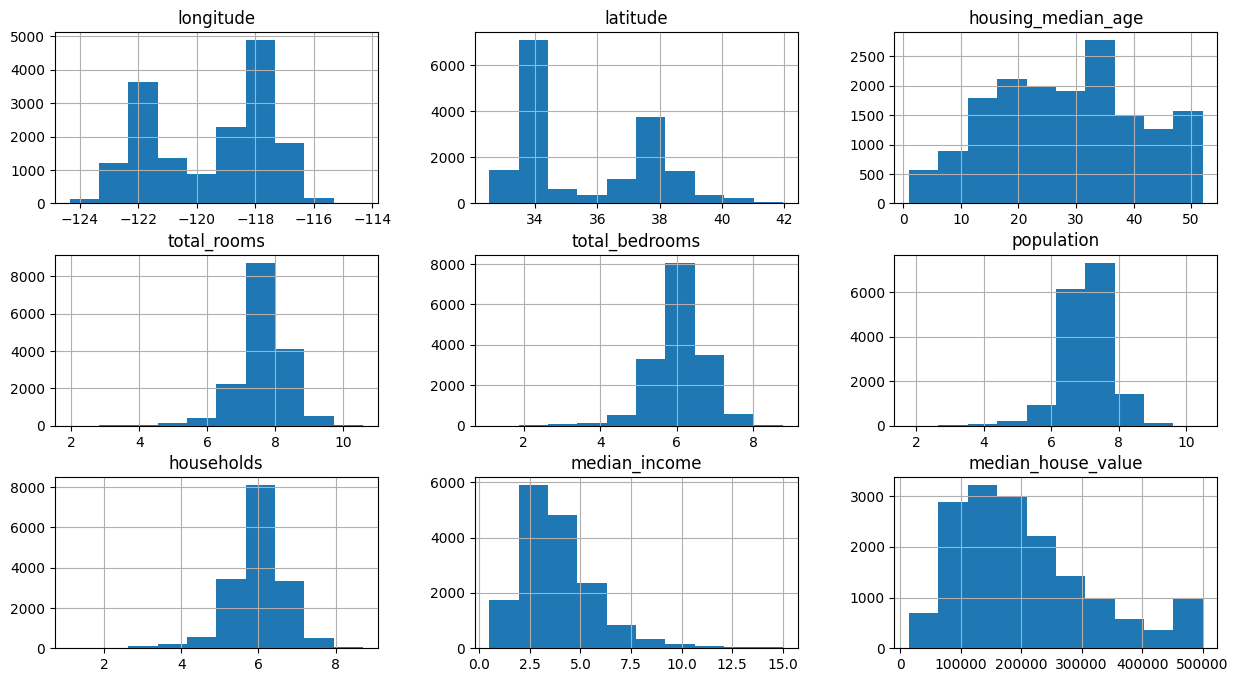

In [ ]:
train_data.hist(figsize=(15,8))

onehotencode them into binary form true or false values for categorical values



In [ ]:
train_data=train_data.join(pd.get_dummies(train_data.ocean_proximity)).drop(['ocean_proximity'],axis=1)

In [ ]:
train_data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
5679,-118.29,33.71,40.0,7.405496,6.156979,6.660575,6.033086,3.1071,464300.0,False,False,False,False,True
16332,-121.34,38.03,20.0,8.346168,6.622736,7.636270,6.572283,4.4063,130800.0,False,True,False,False,False
693,-122.11,37.70,23.0,7.432484,6.135565,6.720220,6.095825,2.1552,161400.0,False,False,False,True,False
1672,-122.20,38.04,31.0,8.016318,6.216606,7.120444,6.190315,5.6022,197000.0,False,False,False,True,False
1548,-121.94,37.75,17.0,7.847763,5.916202,7.122060,5.934894,6.2781,269800.0,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5578,-118.30,33.85,38.0,4.820282,3.610918,4.962845,3.713572,2.3942,200000.0,True,False,False,False,False
15120,-116.93,32.85,5.0,8.322880,6.898715,7.926964,6.809039,3.1142,150000.0,True,False,False,False,False
16593,-121.42,37.73,2.0,7.894691,5.976351,6.784457,5.605802,5.9934,196700.0,False,True,False,False,False
4876,-118.28,34.03,25.0,7.249926,6.311735,7.085064,6.159095,1.2989,225000.0,True,False,False,False,False


<Axes: >

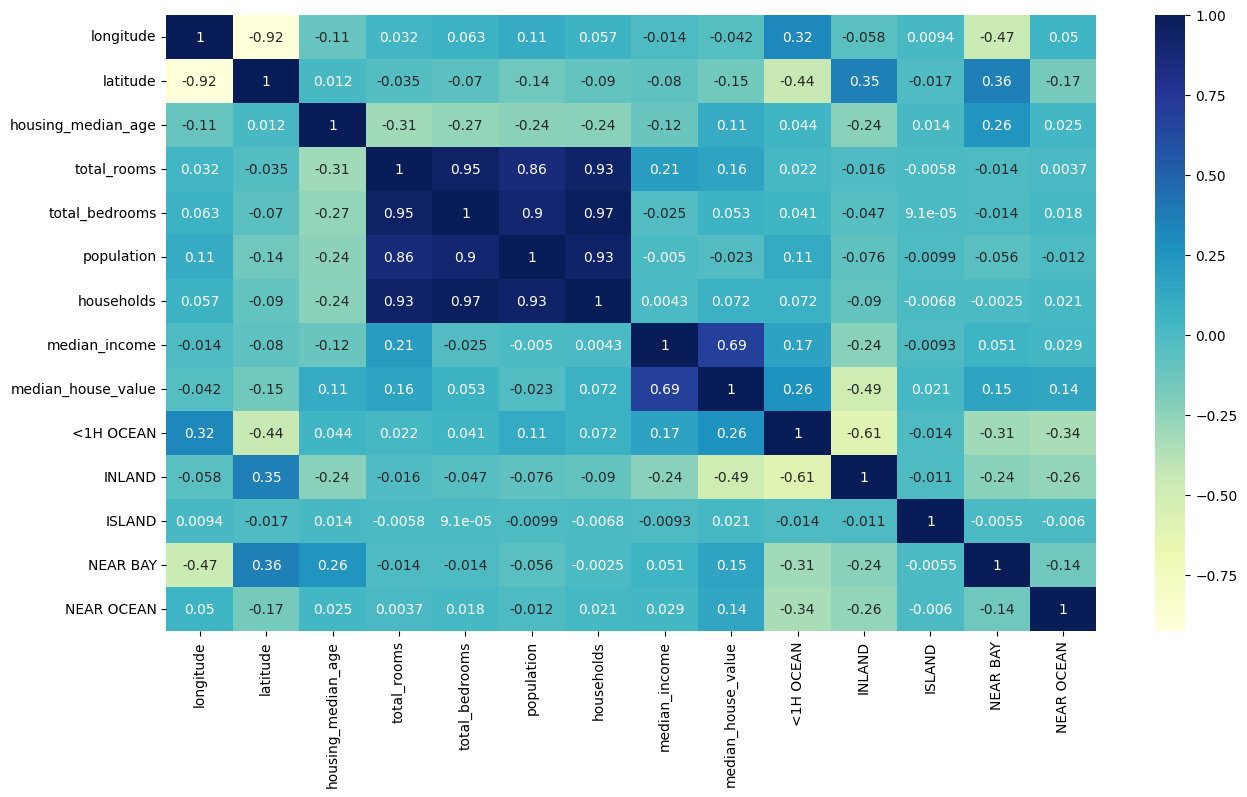

In [ ]:
plt.figure(figsize=(15,8))
sns.heatmap(train_data.corr(),
            annot=True,
            cmap="YlGnBu")



<Axes: xlabel='latitude', ylabel='longitude'>

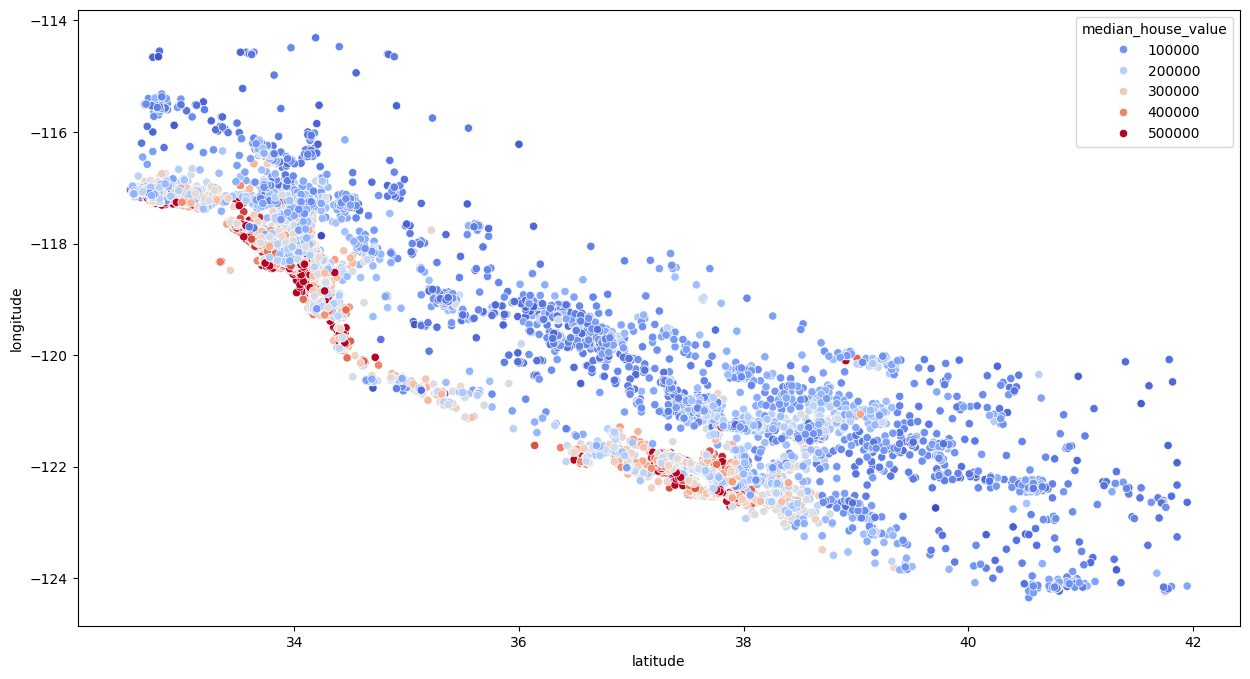

In [ ]:
plt.figure(figsize=(15,8))
sns.scatterplot(x="latitude",y="longitude",data=train_data,hue="median_house_value", palette="coolwarm")

feature engineering


In [ ]:
train_data['bedroom_ratio']= train_data['total_bedrooms']/train_data['total_rooms']
train_data['household-room']=train_data['total_rooms']/train_data['households']



training linear model


In [ ]:
x_train = train_data.drop(['median_house_value'], axis=1)
y_train = train_data['median_house_value']

reg = LinearRegression()
reg.fit(x_train, y_train)

LinearRegression()

In [ ]:
LinearRegression()

LinearRegression()

In [ ]:
test_data = x_test.join(y_test)

test_data['total_rooms'] = np.log(test_data['total_rooms'] + 1)
test_data['total_bedrooms'] = np.log(test_data['total_bedrooms'] + 1)
test_data['population'] = np.log(test_data['population'] + 1)
test_data['households'] = np.log(test_data['households'] + 1)

test_data = test_data.join(
    pd.get_dummies(test_data['ocean_proximity'])
).drop(['ocean_proximity'], axis=1)

test_data['bedroom_ratio'] = (
    test_data['total_bedrooms'] / test_data['total_rooms']
)

test_data['household-room'] = (
    test_data['total_rooms'] / test_data['households']
)

test_data = test_data.reindex(
    columns=train_data.columns,
    fill_value=0
)

In [ ]:
x_test = test_data.drop(['median_house_value'], axis=1)
y_test = test_data['median_house_value']

In [ ]:
train_data


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN,bedroom_ratio,household-room
5679,-118.29,33.71,40.0,7.405496,6.156979,6.660575,6.033086,3.1071,464300.0,False,False,False,False,True,0.831407,1.227480
16332,-121.34,38.03,20.0,8.346168,6.622736,7.636270,6.572283,4.4063,130800.0,False,True,False,False,False,0.793506,1.269904
693,-122.11,37.70,23.0,7.432484,6.135565,6.720220,6.095825,2.1552,161400.0,False,False,False,True,False,0.825507,1.219275
1672,-122.20,38.04,31.0,8.016318,6.216606,7.120444,6.190315,5.6022,197000.0,False,False,False,True,False,0.775494,1.294977
1548,-121.94,37.75,17.0,7.847763,5.916202,7.122060,5.934894,6.2781,269800.0,True,False,False,False,False,0.753871,1.322309
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5578,-118.30,33.85,38.0,4.820282,3.610918,4.962845,3.713572,2.3942,200000.0,True,False,False,False,False,0.749109,1.298018
15120,-116.93,32.85,5.0,8.322880,6.898715,7.926964,6.809039,3.1142,150000.0,True,False,False,False,False,0.828885,1.222328
16593,-121.42,37.73,2.0,7.894691,5.976351,6.784457,5.605802,5.9934,196700.0,False,True,False,False,False,0.757009,1.408307
4876,-118.28,34.03,25.0,7.249926,6.311735,7.085064,6.159095,1.2989,225000.0,True,False,False,False,False,0.870593,1.177109


In [ ]:
reg.score(x_test, y_test)


0.6651099254907178

random forest model

In [ ]:
from sklearn.ensemble import RandomForestRegressor

forest = RandomForestRegressor()

forest.fit(x_train,y_train)

RandomForestRegressor()

In [ ]:
RandomForestRegressor()

RandomForestRegressor()

In [ ]:
forest.score(x_test,y_test)

0.8173951153139853

By providing parameter grid by grid search k fold validation basically for all combination and evalute the parameter


In [ ]:

from sklearn.model_selection import GridSearchCV

forest = RandomForestRegressor()

param_grid = {
     "n_estimators":[10,30],
     "min_samples_split":[2,4],
     "max_depth":[4,8]
}

grid_search = GridSearchCV(forest, param_grid,cv=5,scoring="neg_mean_squared_error")

grid_search.fit(x_train,y_train)


GridSearchCV(cv=5, estimator=RandomForestRegressor(),
             param_grid={'max_depth': [4, 8], 'min_samples_split': [2, 4],
                         'n_estimators': [10, 30]},
             scoring='neg_mean_squared_error')

In [ ]:
grid_search.best_estimator_

RandomForestRegressor(max_depth=8, min_samples_split=4, n_estimators=30)

In [ ]:
grid_search.best_estimator_.score(x_test,y_test)


0.7472354579791203

Finished with the score of 0.7 not bad but also not the best.
Now to make it simpler we can create a pipeline so it automatically handles the [missing values → scaling → categorical encoding → Random Forest → prediction.] part and then we can give our input features and get the price predicted.